In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

In [2]:
PROCESSED_DIR = Path("../data/processed")

train = pd.read_csv(PROCESSED_DIR / "train.csv")
validation = pd.read_csv(PROCESSED_DIR / "validation.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

print(train.shape, validation.shape, test.shape)

(58823, 6) (12611, 6) (12632, 6)


In [3]:
X_train_text = train["text"].astype(str)
X_val_text = validation["text"].astype(str)
X_test_text = test["text"].astype(str)

y_train = train["target"].astype(int)
y_val = validation["target"].astype(int)
y_test = test["target"].astype(int)

print("Train:", len(X_train_text), y_train.value_counts().to_dict())
print("Validation:", len(X_val_text), y_val.value_counts().to_dict())
print("Test:", len(X_test_text), y_test.value_counts().to_dict())

Train: 58823 {0: 40024, 1: 18799}
Validation: 12611 {0: 8578, 1: 4033}
Test: 12632 {0: 8579, 1: 4053}


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

VECTORIZER_CONFIG = {
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_features": 100_000,
    "sublinear_tf": True,
    "strip_accents": "unicode",
    "dtype": np.float32,
}

vectorizer = TfidfVectorizer(**VECTORIZER_CONFIG)

X_train = vectorizer.fit_transform(X_train_text)
X_val = vectorizer.transform(X_val_text)
X_test = vectorizer.transform(X_test_text)

print("Train TF-IDF shape:", X_train.shape)
print("Validation TF-IDF shape:", X_val.shape)
print("Test TF-IDF shape:", X_test.shape)

Train TF-IDF shape: (58823, 100000)
Validation TF-IDF shape: (12611, 100000)
Test TF-IDF shape: (12632, 100000)


In [5]:
class SparseBatchGenerator(keras.utils.Sequence):
    def __init__(self, X, y, batch_size=128, shuffle=True):
        super().__init__()
        self.X = X
        self.y = np.asarray(y, dtype=np.float32)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(X.shape[0])
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = min((index + 1) * self.batch_size, len(self.indices))

        batch_indices = self.indices[start:end]

        X_batch = self.X[batch_indices].toarray().astype(np.float32)
        y_batch = self.y[batch_indices]

        return X_batch, y_batch

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

In [6]:
train_gen = SparseBatchGenerator(
    X_train,
    y_train,
    batch_size=128,
    shuffle=True
)

val_gen = SparseBatchGenerator(
    X_val,
    y_val,
    batch_size=128,
    shuffle=False
)

In [7]:
model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),

    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │     6,400,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,402,177 (24.42 MB)

 Trainable params: 6,402,177 (24.42 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer=keras.optimizers.Adam(
    learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
    "accuracy",
    keras.metrics.AUC(name="auc")
]
)

In [9]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

In [10]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    callbacks=[early_stopping],
    verbose=2
)

Epoch 1/20
460/460 - 7s - 16ms/step - accuracy: 0.8311 - auc: 0.9050 - loss: 0.5167 - val_accuracy: 0.9497 - val_auc: 0.9932 - val_loss: 0.2832
Epoch 2/20
460/460 - 7s - 15ms/step - accuracy: 0.9694 - auc: 0.9948 - loss: 0.1781 - val_accuracy: 0.9810 - val_auc: 0.9983 - val_loss: 0.0995
Epoch 3/20
460/460 - 7s - 14ms/step - accuracy: 0.9875 - auc: 0.9988 - loss: 0.0722 - val_accuracy: 0.9854 - val_auc: 0.9988 - val_loss: 0.0564
Epoch 4/20
460/460 - 7s - 14ms/step - accuracy: 0.9936 - auc: 0.9996 - loss: 0.0391 - val_accuracy: 0.9886 - val_auc: 0.9990 - val_loss: 0.0418
Epoch 5/20
460/460 - 7s - 14ms/step - accuracy: 0.9967 - auc: 0.9998 - loss: 0.0234 - val_accuracy: 0.9894 - val_auc: 0.9991 - val_loss: 0.0352
Epoch 6/20
460/460 - 7s - 14ms/step - accuracy: 0.9982 - auc: 0.9999 - loss: 0.0148 - val_accuracy: 0.9896 - val_auc: 0.9991 - val_loss: 0.0323
Epoch 7/20
460/460 - 7s - 14ms/step - accuracy: 0.9988 - auc: 0.9999 - loss: 0.0102 - val_accuracy: 0.9900 - val_auc: 0.9990 - val_loss:

In [11]:
val_probs = model.predict(val_gen, verbose=0).ravel()

In [12]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_val, val_probs)
val_roc_auc = roc_auc_score(y_val, val_probs)

print(f"Validation ROC-AUC: {val_roc_auc:.4f}")

Validation ROC-AUC: 0.9992


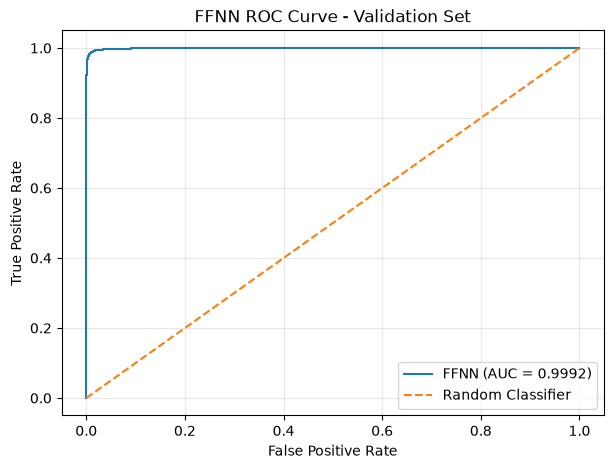

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"FFNN (AUC = {val_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("FFNN ROC Curve - Validation Set")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [14]:
val_preds = (val_probs >= 0.5).astype(int)

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

val_accuracy = accuracy_score(y_val, val_preds)
val_precision = precision_score(y_val, val_preds, average="macro")
val_recall = recall_score(y_val, val_preds, average="macro")
val_f1 = f1_score(y_val, val_preds, average="macro")
val_cm = confusion_matrix(y_val, val_preds)

print(f"Validation Accuracy:        {val_accuracy:.4f}")
print(f"Validation Macro Precision: {val_precision:.4f}")
print(f"Validation Macro Recall:    {val_recall:.4f}")
print(f"Validation Macro F1:        {val_f1:.4f}")
print("\nConfusion Matrix:")
print(val_cm)

Validation Accuracy:        0.9898
Validation Macro Precision: 0.9901
Validation Macro Recall:    0.9864
Validation Macro F1:        0.9882

Confusion Matrix:
[[8542   36]
 [  93 3940]]


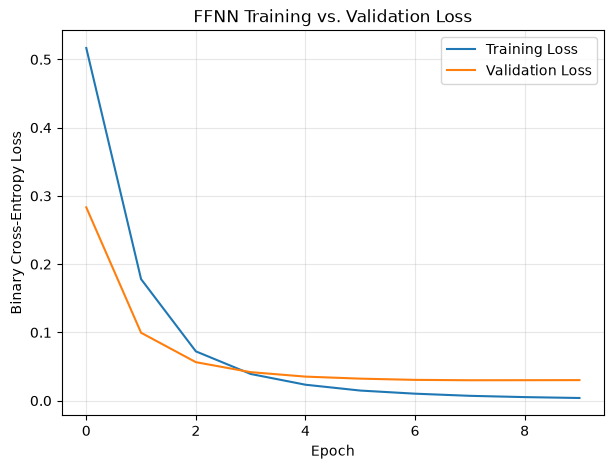

In [16]:
plt.figure(figsize=(7, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("FFNN Training vs. Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

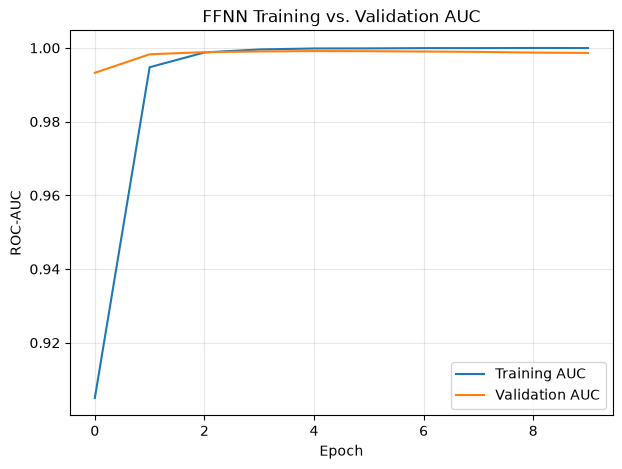

In [17]:
plt.figure(figsize=(7, 5))

plt.plot(history.history["auc"], label="Training AUC")
plt.plot(history.history["val_auc"], label="Validation AUC")

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("FFNN Training vs. Validation AUC")
plt.legend()
plt.grid(alpha=0.3)

plt.show()